# Fading and non-fading memory – a motivation

*Nonlinear Signal Processing – Dynamical Systems, Lecture 1*

In signal processing we usually think of a system as something that turns an **input** $u(t)$ into an **output** $y(t)$. A *dynamical* system does this through an internal **state** $\mathbf z(t)$ that changes in time:

$$
\dot{\mathbf z}(t) = \mathbf f\big(\mathbf z(t),\,u(t)\big),\qquad \mathbf z(0)=\mathbf z_0,\qquad y(t) = g\big(\mathbf z(t)\big).
$$

The state is the system's **memory**: everything the system "knows" about its past is contained in $\mathbf z(t)$. The present state depends on two things – the **initial state** $\mathbf z_0$ and the **input history** $u(s)$, $0\le s\le t$.

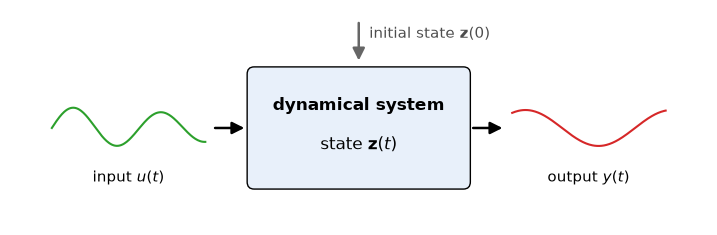

In [2]:
import sys, pathlib
import numpy as np, matplotlib.pyplot as plt
# helper modules are in <repo>/src, this notebook is in <repo>/notebooks/sessions: search upwards for src/
here = pathlib.Path(globals().get('__vsc_ipynb_file__', pathlib.Path.cwd() / 'nb')).parent
root = next(p for p in (here, *here.parents) if (p / 'src' / 'memory_illustrations.py').exists())
sys.path.insert(0, str(root / 'src'))
import memory_illustrations as mi
plt.rcParams.update({'figure.dpi': 100})
mi.block_diagram();

## 1. The memory question

> **How long does the past influence the present?**

We make this precise with a simple thought experiment: take **two identical copies A and B** of a system, start them in **different states** $\mathbf z_A(0)\neq\mathbf z_B(0)$, and drive both with **exactly the same input** $u(t)$. Then watch what happens to their difference.

**Fading memory.** The influence of the initial state (and of inputs long ago) dies out:

$$
\lim_{t\to\infty}\big\|\mathbf z_A(t)-\mathbf z_B(t)\big\| = 0 \qquad\text{for every input } u .
$$

After a while the state is determined by the **recent input alone** – the system has "forgotten" where it came from.

**Non-fading memory.** Some information about the past is kept forever: the copies **never** become equal, although they receive the same input.

Both are useful – for very different tasks. This notebook shows what the two kinds of memory look like, from the simplest linear example to nonlinear systems.

## 2. The simplest example: leaky vs. ideal integrator

Consider the scalar systems

$$
\text{leaky integrator:}\quad \dot x = -\frac{x}{T} + u(t), \qquad\qquad \text{ideal integrator:}\quad \dot x = u(t).
$$

Both can be solved explicitly (variation of constants):

$$
x(t) = \underbrace{e^{-t/T}\,x(0)}_{\text{memory of the start}} \;+\; \int_0^t \underbrace{e^{-(t-s)/T}}_{h(t-s)}\,u(s)\,\mathrm ds .
$$

* The first term – the **initial state** – decays with the time constant $T$.
* The second term is a weighted sum of all past inputs. An input that happened $\tau = t-s$ ago is weighted with the **memory kernel** $h(\tau)=e^{-\tau/T}$: recent inputs count fully, old ones are faded out. $T$ is the **memory time**.
* For the ideal integrator ($T\to\infty$) the kernel is $h(\tau)=1$: the start is never forgotten and every input, however old, counts with the same weight.

The difference of two copies, $d = x_A-x_B$, does not depend on the input at all:

$$
\dot d = -\frac{d}{T}\;\Rightarrow\; d(t) = d(0)\,e^{-t/T}\quad\text{(leaky)},\qquad\qquad \dot d = 0 \;\Rightarrow\; d(t)=d(0)\quad\text{(ideal)}.
$$

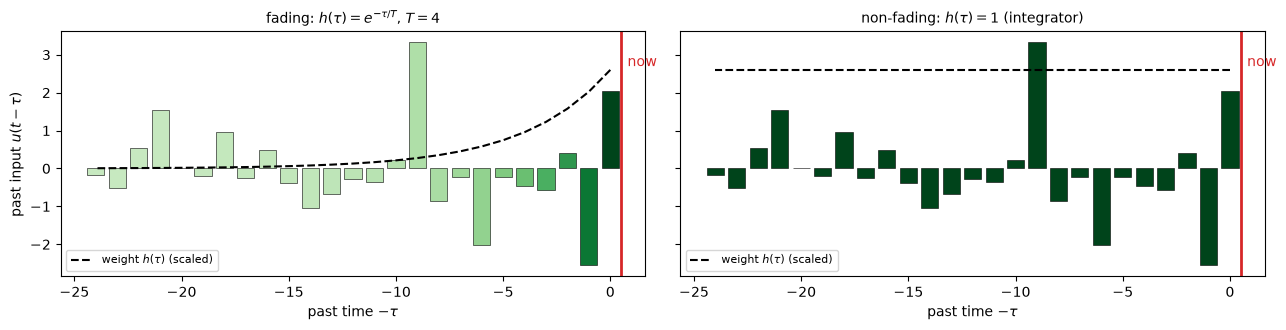

In [3]:
mi.memory_kernel(T=4);

Below: **top** – two copies with the same input; the leaky integrator forgets its start, the ideal integrator keeps the offset forever.
**Bottom** – 25 runs driven only by random noise. The leaky integrator forgets old noise, so the spread stays bounded ($\mathrm{Var}\,x\to\sigma^2T/2$). The ideal integrator remembers *all* noise it ever received: the runs drift apart like a random walk ($\mathrm{Var}\,x = \sigma^2 t$).

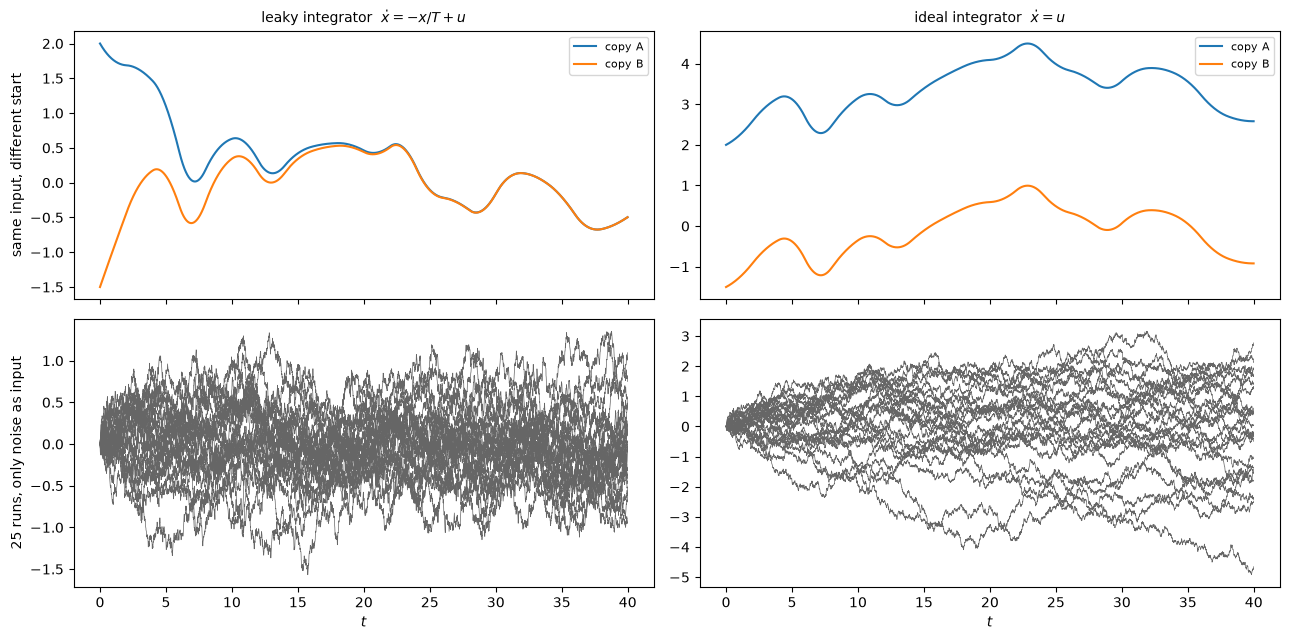

In [4]:
mi.two_integrators(T=4);

**Lesson:** memory is a double-edged sword. A system that keeps information about the past also keeps the *noise* of the past.

## 3. A picture for nonlinear systems: balls in landscapes

For nonlinear systems we can no longer write down the solution, but a mechanical picture helps. A ball moves with strong friction in a landscape $V(x)$ and is pushed by a small input:

$$
\dot x = V(x) + u(t).
$$

The ball always rolls downhill; where it can come to rest is decided by the **shape of the landscape**. Two balls (copies A and B, faded positions = earlier times) are started at different places and receive the same small input:

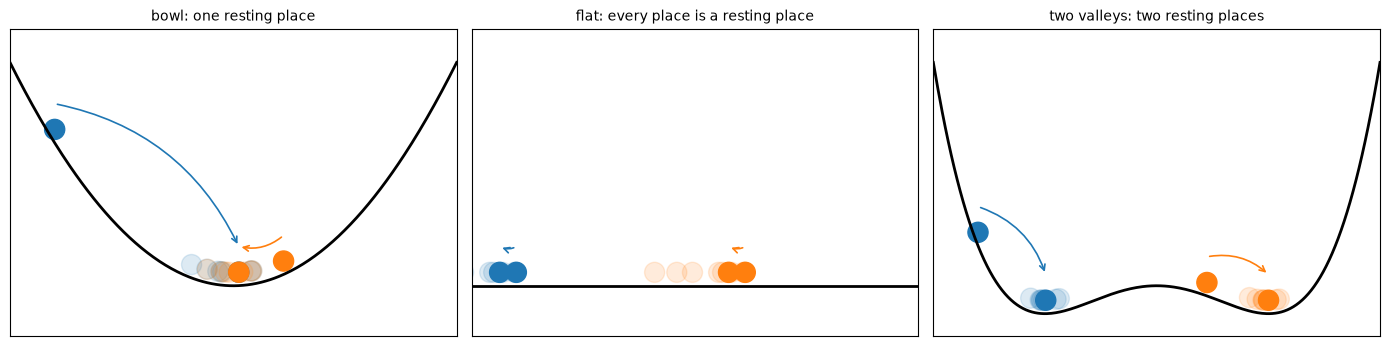

In [11]:
mi.landscapes();